
# Introducción al Proyecto: OilyGiant - Selección de Regiones para Nuevos Pozos Petroleros

## Contexto del Problema
La compañía de extracción de petróleo OilyGiant desea abrir 200 nuevos pozos de petróleo, para lo cual realizará una inversión de 100 millones de dólares. Cada pozo deberá producir al menos un valor de 500,000 dólares en unidades para evitar pérdidas.
## Objetivo del Proyecto
Ayudar a OilyGiant a identificar la mejor región para abrir los pozos, basándonos en datos de muestras de crudo de tres diferentes regiones, así como los parámetros de cada pozo petrolero de dichas regiones.
## Datos Disponibles
Disponemos de tres datasets que contienen la exploración geológica de tres regiones, con información de los parámetros recogidos de pozos petrolíferos en cada región: calidad de crudo y volumen de reservas. Las variables incluyen:
+ id — identificador único de pozo de petróleo
+ f0, f1, f2 — tres características de los puntos (su significado específico no es importante, pero las características en sí son significativas)
+ product — volumen de reservas en el pozo de petróleo (miles de barriles).
## Metodología
1. Exploración, análisis y preparación de los datos.
2. Creación, entrenamiento y prueba de un modelo de regresión lineal para cada región que pueda predecir el volumen de reservas en los pozos nuevos y así seleccionar la mejor región que proporcione el beneficio más alto de acuerdo a la selección de los 200 mejores puntos de 500 con los que cuenta cada región.
3. Calcularemos el volumen mínimo de reservas que debe producir cada pozo para que la inversión sea rentable, considerando el presupuesto disponible de 100 millones de dólares y el precio por unidad, que es de 4500 dólares.
4. Utilizaremos la técnica de bootstrapping con 1000 muestras para analizar riesgos y ganancias potenciales. El riesgo máximo aceptable será de menos del 2.5% de probabilidad de pérdidas.


## Paso 1: Carga y Preparación de Datos

In [1]:
#Importación de librerías

import pandas as pd
import numpy as np
from matplotlib import pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error



In [2]:
#Carga de los 3 archivos
df_gd0 = pd.read_csv('/datasets/geo_data_0.csv', sep=',', encoding='utf-8', quotechar= '"')
df_gd1 = pd.read_csv('/datasets/geo_data_1.csv', sep=',', encoding='utf-8', quotechar= '"')
df_gd2 = pd.read_csv('/datasets/geo_data_2.csv', sep=',', encoding='utf-8', quotechar= '"')

#información general
print("Información general del Data Frame gd0:")
print(df_gd0.info())
print()
print("Información general del Data Frame gd1:")
print(df_gd1.info())
print()
print("Información general del Data Frame gd2:")
print(df_gd2.info())

Información general del Data Frame gd0:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 5 columns):
 #   Column   Non-Null Count   Dtype  
---  ------   --------------   -----  
 0   id       100000 non-null  object 
 1   f0       100000 non-null  float64
 2   f1       100000 non-null  float64
 3   f2       100000 non-null  float64
 4   product  100000 non-null  float64
dtypes: float64(4), object(1)
memory usage: 3.8+ MB
None

Información general del Data Frame gd1:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100000 entries, 0 to 99999
Data columns (total 5 columns):
 #   Column   Non-Null Count   Dtype  
---  ------   --------------   -----  
 0   id       100000 non-null  object 
 1   f0       100000 non-null  float64
 2   f1       100000 non-null  float64
 3   f2       100000 non-null  float64
 4   product  100000 non-null  float64
dtypes: float64(4), object(1)
memory usage: 3.8+ MB
None

Información general del Data Frame gd2:


### Exploración geo_data_0

In [3]:
#Exploración región 0
print(f"Forma del DataFrame: {df_gd0.shape}")
print(f"Valores faltantes por columna:")
print(df_gd0.isnull().sum())
print()
print("Vista del DataFrame:")
display(df_gd0.head())
print()
print("Descripción estadística del DataFrame:")
display(df_gd0.describe())
print()
print("Valores duplicados en el DataFrame:")
print(df_gd0.duplicated().sum())

Forma del DataFrame: (100000, 5)
Valores faltantes por columna:
id         0
f0         0
f1         0
f2         0
product    0
dtype: int64

Vista del DataFrame:


,id,f0,f1,f2,product
0,txEyH,0.705745,-0.497823,1.221170,105.280062
1,2acmU,1.334711,-0.340164,4.365080,73.037750
2,409Wp,1.022732,0.151990,1.419926,85.265647
3,iJLyR,-0.032172,0.139033,2.978566,168.620776
4,Xdl7t,1.988431,0.155413,4.751769,154.036647



Descripción estadística del DataFrame:


,f0,f1,f2,product
count,100000.000000,100000.000000,100000.000000,100000.000000
mean,0.500419,0.250143,2.502647,92.500000
std,0.871832,0.504433,3.248248,44.288691
min,-1.408605,-0.848218,-12.088328,0.000000
25%,-0.072580,-0.200881,0.287748,56.497507
50%,0.502360,0.250252,2.515969,91.849972
75%,1.073581,0.700646,4.715088,128.564089
max,2.362331,1.343769,16.003790,185.364347



Valores duplicados en el DataFrame:
0


### Exploración geo_data_1

In [4]:
#Exploración región 1
print(f"Forma del DataFrame: {df_gd1.shape}")
print(f"Valores faltantes por columna:")
print(df_gd1.isnull().sum())
print()
print("Vista del DataFrame:")
display(df_gd1.head())
print()
print("Descripción estadística del DataFrame:")
display(df_gd1.describe())
print()
print("Valores duplicados en el DataFrame:")
print(df_gd1.duplicated().sum())

Forma del DataFrame: (100000, 5)
Valores faltantes por columna:
id         0
f0         0
f1         0
f2         0
product    0
dtype: int64

Vista del DataFrame:


,id,f0,f1,f2,product
0,kBEdx,-15.001348,-8.276000,-0.005876,3.179103
1,62mP7,14.272088,-3.475083,0.999183,26.953261
2,vyE1P,6.263187,-5.948386,5.001160,134.766305
3,KcrkZ,-13.081196,-11.506057,4.999415,137.945408
4,AHL4O,12.702195,-8.147433,5.004363,134.766305



Descripción estadística del DataFrame:


,f0,f1,f2,product
count,100000.000000,100000.000000,100000.000000,100000.000000
mean,1.141296,-4.796579,2.494541,68.825000
std,8.965932,5.119872,1.703572,45.944423
min,-31.609576,-26.358598,-0.018144,0.000000
25%,-6.298551,-8.267985,1.000021,26.953261
50%,1.153055,-4.813172,2.011479,57.085625
75%,8.621015,-1.332816,3.999904,107.813044
max,29.421755,18.734063,5.019721,137.945408



Valores duplicados en el DataFrame:
0


### Exploración geo_data_2

In [5]:
#Exploración región 2
print(f"Forma del DataFrame: {df_gd2.shape}")
print(f"Valores faltantes por columna:")
print(df_gd2.isnull().sum())
print()
print("Vista del DataFrame:")
display(df_gd2.head())
print()
print("Descripción estadística del DataFrame:")
display(df_gd2.describe())
print()
print("Valores duplicados en el DataFrame:")
print(df_gd2.duplicated().sum())

Forma del DataFrame: (100000, 5)
Valores faltantes por columna:
id         0
f0         0
f1         0
f2         0
product    0
dtype: int64

Vista del DataFrame:


,id,f0,f1,f2,product
0,fwXo0,-1.146987,0.963328,-0.828965,27.758673
1,WJtFt,0.262778,0.269839,-2.530187,56.069697
2,ovLUW,0.194587,0.289035,-5.586433,62.871910
3,q6cA6,2.236060,-0.553760,0.930038,114.572842
4,WPMUX,-0.515993,1.716266,5.899011,149.600746



Descripción estadística del DataFrame:


,f0,f1,f2,product
count,100000.000000,100000.000000,100000.000000,100000.000000
mean,0.002023,-0.002081,2.495128,95.000000
std,1.732045,1.730417,3.473445,44.749921
min,-8.760004,-7.084020,-11.970335,0.000000
25%,-1.162288,-1.174820,0.130359,59.450441
50%,0.009424,-0.009482,2.484236,94.925613
75%,1.158535,1.163678,4.858794,130.595027
max,7.238262,7.844801,16.739402,190.029838



Valores duplicados en el DataFrame:
0


Comparación estadística entre los 3 datasets:


df_gd0                                               \
                  f0             f1             f2        product   
count  100000.000000  100000.000000  100000.000000  100000.000000   
mean        0.500419       0.250143       2.502647      92.500000   
std         0.871832       0.504433       3.248248      44.288691   
min        -1.408605      -0.848218     -12.088328       0.000000   
25%        -0.072580      -0.200881       0.287748      56.497507   
50%         0.502360       0.250252       2.515969      91.849972   
75%         1.073581       0.700646       4.715088     128.564089   
max         2.362331       1.343769      16.003790     185.364347   

              df_gd1                                               \
                  f0             f1             f2        product   
count  100000.000000  100000.000000  100000.000000  100000.000000   
mean        1.141296      -4.796579       2.494541      68.825000   
std         8.965932       5.119872       1.703572      45.944423   
min       -31.609576     -26.358598      -0.018144       0.000000   
25%        -6.298551      -8.267985       1.000021      26.953261   
50%         1.153055      -4.813172       2.011479      57.085625   
75%         8.621015      -1.332816       3.999904     107.813044   
max        29.421755      18.734063       5.019721     137.945408   

              df_gd2                                               
                  f0             f1             f2        product  
count  100000.000000  100000.000000  100000.000000  100000.000000  
mean        0.002023      -0.002081       2.495128      95.000000  
std         1.732045       1.730417       3.473445      44.749921  
min        -8.760004      -7.084020     -11.970335       0.000000  
25%        -1.162288      -1.174820       0.130359      59.450441  
50%         0.009424      -0.009482       2.484236      94.925613  
75%         1.158535       1.163678       4.858794     130.595027  
max         7.238262       7.844801      16.739402     190.029838


Gráficos de barras para visualización de comparación estadística de los 3 datasets


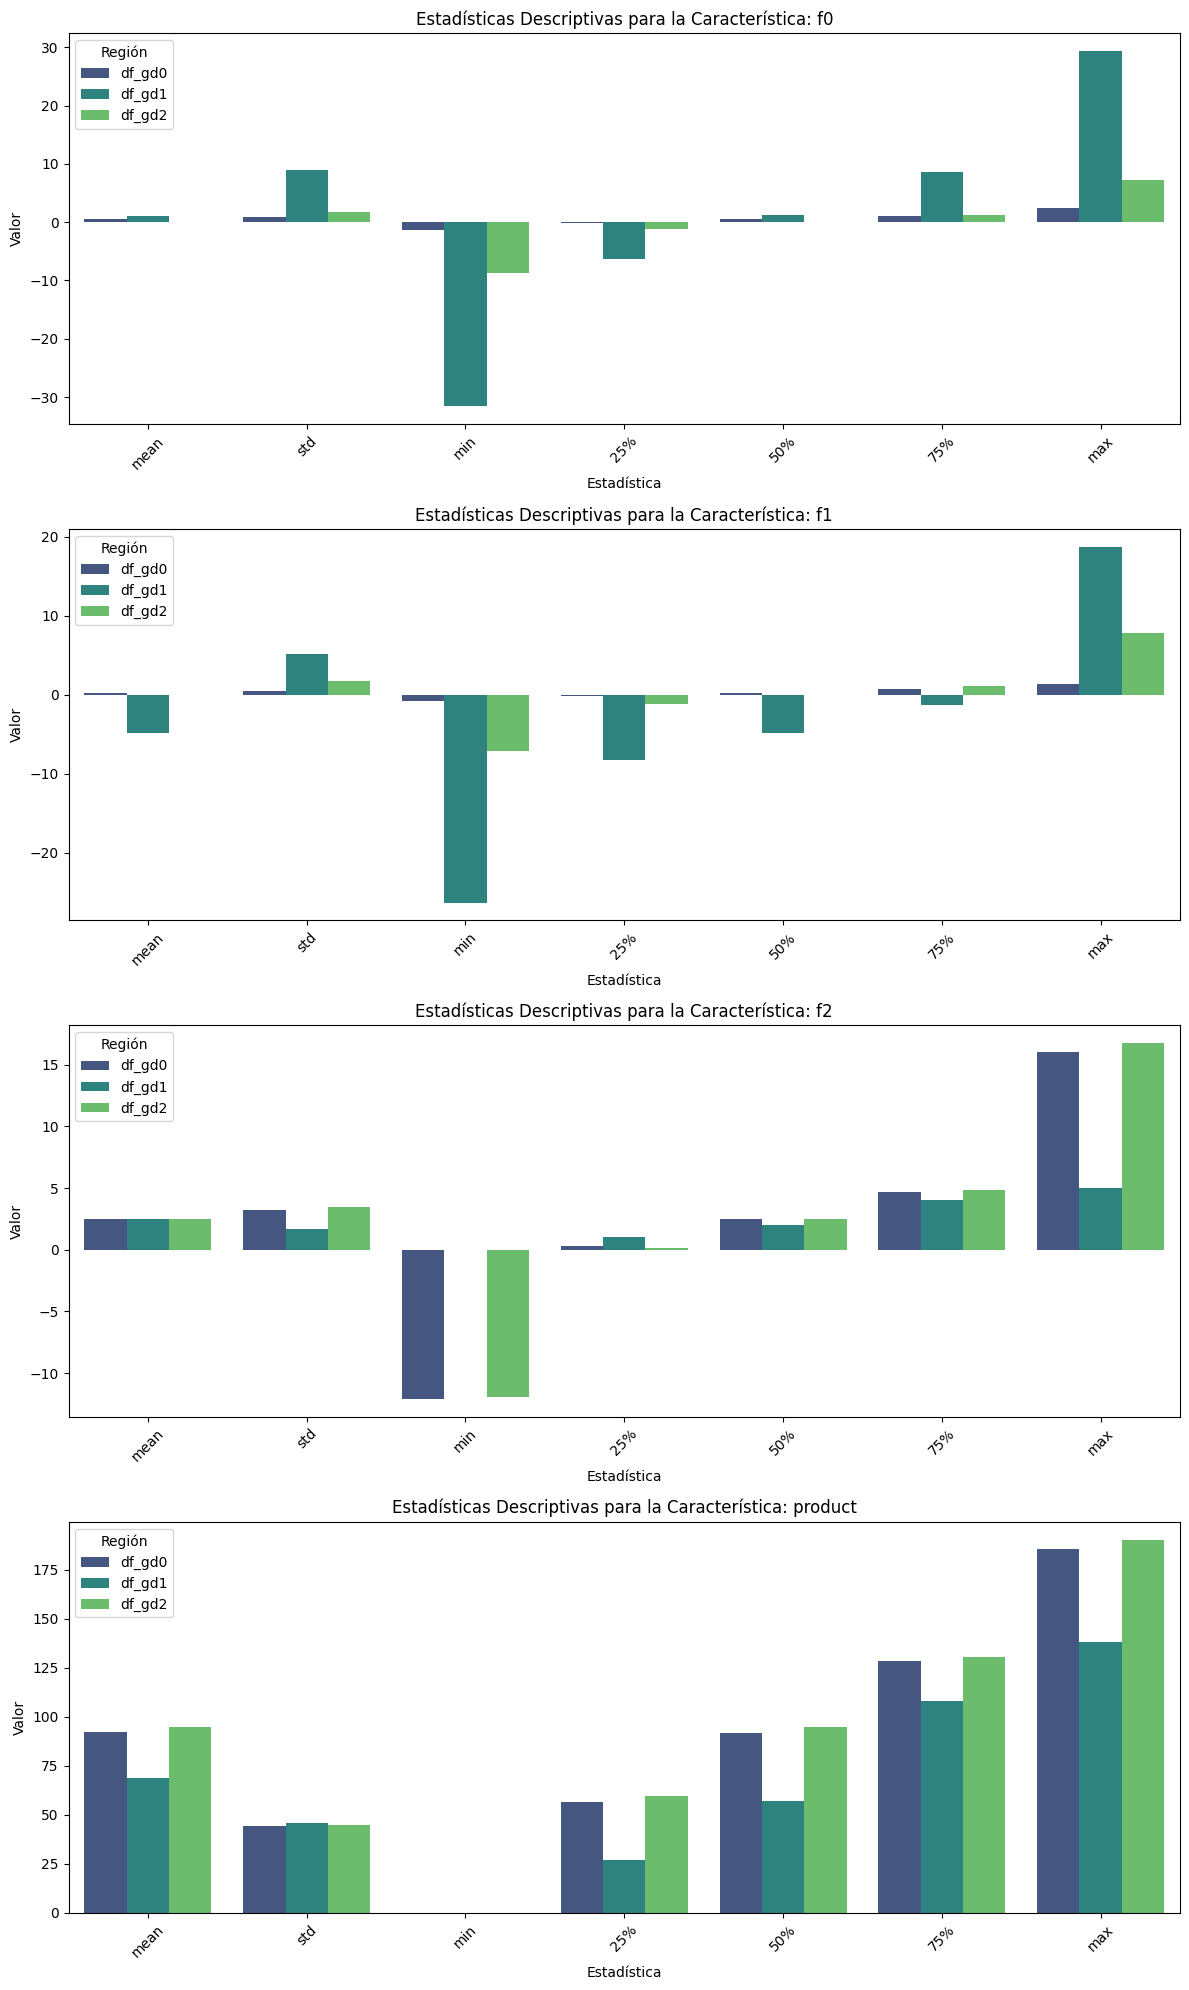

In [6]:
#Comparación Estadística entre los 3 data sets
print("Comparación estadística entre los 3 datasets:")
display(pd.concat([df_gd0.describe(), df_gd1.describe(), df_gd2.describe()], axis=1, keys=['df_gd0', 'df_gd1', 'df_gd2']))
print()
#Gráfico de barras para visualización 
print("Gráficos de barras para visualización de comparación estadística de los 3 datasets")
describe_dfs = {
    'df_gd0': df_gd0.describe(),
    'df_gd1': df_gd1.describe(),
    'df_gd2': df_gd2.describe()
}

# Características (features) a analizar (exluyendo'id')
features = ['f0', 'f1', 'f2', 'product']

# Crear una lista para almacenar los datos para los graficar
plot_data = []

for region, desc_df in describe_dfs.items():
    for feature in features:
        if feature in desc_df.columns:
            for stat in ['mean', 'std', 'min', '25%', '50%', '75%', 'max']:
                if stat in desc_df.index:
                    plot_data.append({
                        'Region': region,
                        'Feature': feature,
                        'Statistic': stat,
                        'Value': desc_df.loc[stat, feature]
                    })

df_plot = pd.DataFrame(plot_data)

# Graficar las estadísticas descriptivas
fig, axes = plt.subplots(nrows=len(features), ncols=1, figsize=(12, 5 * len(features)))
axes = axes.flatten()

for i, feature in enumerate(features):
    sns.barplot(
        data=df_plot[df_plot['Feature'] == feature],
        x='Statistic',
        y='Value',
        hue='Region',
        ax=axes[i],
        palette='viridis'
    )
    axes[i].set_title(f'Estadísticas Descriptivas para la Característica: {feature}')
    axes[i].set_ylabel('Valor')
    axes[i].set_xlabel('Estadística')
    axes[i].tick_params(axis='x', rotation=45)
    axes[i].legend(title='Región')

plt.tight_layout()
plt.show()


### Observaciones iniciales
#### Carga y estructura: 
Hemos cargado exitosamente los tres Datasets (`df_gd0`, `df_gd1`, `df_gd2`), cada uno conteniendo 100,000 entradas y 5 colulmnas 
+ Tamaño: 100,000 pozos con 5 columnas (`id`,`f0`,`f1`, `f2`, `product`)
+ Calidad: no se encontraron valores nulos ni duplicados en ninguno de los DataFrames, lo que indica una buena calidad de los datos.
#### Variables del data set
+ Variables numéricas: `f0`,`f1`,`f2`,`product`.
+ Variables categóricas: `id`.
+ Vaariable objetivo: `product`. (volumen de reservas en el pozo petrolero en miles de barriles)
#### Estadísticas Descriptivas Generales:
Al comparar las estadísticas descriptivas de los 3 DataFrames, observamos diferencias clave: 
- `df_gd0`y `df_gd2`: presentan distribuciones de características (`f0`,`f1`,`f2`) relativamente similares, con medias cercanas a 0 y rangos de valores acotados. Ambas regiones muestran un volumen promedio de reservas (`product`) más alto y una mayor dispersión en los valores máximos de `product`en  comparación con  `df_gd1`.
- `df_gd1`: Se destaca por tener rangos mucho más amplios para f0 y f1 (con valores mínimos y máximos que se extienden significativamente más allá de las otras dos regiones) y una desviación estándar mayor en estas características. Sin embargo, su volumen promedio de reservas (`product`) es notablemente inferior en comparación con `df_gd0` y `df_gd2`, y sus valores de `product` parecen tener menos variabilidad continua, lo cual es visible en los cuartiles y el rango.
#### Visualización:
Los gráficos de barras confirman estas observaciones, mostrando claramente las diferencias en las medias, desviaciones estándar, mínimos, máximos y cuartiles para cara característica y región. La región `df_gd1` muestra un comportamiento distinto, especialmente en `f0` y `f1` con valores extremos, y un `product`consistentemente más bajo.
+ Características `f0`,`f1`,`f2`: Se pueden ver diferencias claras en la distribución de estas características entre las regiones. Por ejemplo, `df_gd1`muestra rangos significativamente más amplios (valores mínimos y máximos) y una desviación estándar mayor para `f0`y `f1`en comparación con `df_gd0`y `df_gd2`.
+ Variable objetivo `product`(Volúmen de Reservas): Es la variable más crítica. Observamos que `df_gd0`y `df_gd2`tienen valores promedio de volumen de reservas más altos ( al rededor de 92.5 y 95 mil barriles respecitvamente), en comparación con `df_gd1`(aproximadamente 68.8 mil barriles). Esto sugiere que `df_gd0`y `df_gd2`podrían ser regiones con mayor potencial de producción. También es útil observar la desviación estándar y los cuartiles para entender la variabilidad de la producción en cada región.
Estos gráficos facilitan la identificación rápida de tendencias y diferencias importantes entre las regiones, lo que será crucial par atomar una decisión informada sobre dónde ubicar los nuevos pozos petroleros.
En general `df_gd0`y `df_gd2`parecen ser las regiones mpas prometedoras en términos de vollumen de reservas promedio, mientras que `df_gd1`muestra características de distribución peculiares que podrían influir en el modelado. El siguiente paso será entrenar y evaluar modelos de regresión lineal para cada una de las regiones. 


## Paso 2: Entrenamiento y Evaluación del Modelo por Región

Se entrenará y probará un modelo de regresión lineal para cada una de las regiones. 
La división de los datos será en proporción 75:25, es decir 75% de los datos estrán destinados para entrenamiento y el 25% de los datos para validación. 
Entrenaremos al modelo y haremos las predicciones para el conjunto de validación, guardando las predicciones y respuestas correctas para el conjunto de validación y evaluaremos su desempeño con RSME.
Todo lo anterior se hará mediante una función para reutilizarla en las demás regiones.


### Definición de la función de entrenamiento

Vamos a crear una función que incluya lo siguiente:
1. Separar features (`f0`, `f1`y `f2`)  y target (`product`).
2. Dividir los datos de entrenamiento (75%) y validación (25%).
3. Entrenar el modelo de regresión lineal.
4. Hacer predicciones sobre el conjunto de validación.
5. Calcular y mostrar el RMSE y la media de las predicciones.
6. Retomar las predicciones y los valores reales.


In [7]:
#Función de entrenamiento y predicción

def train_and_predict(df):
    #Separar features y target
    features = df.drop(['id', 'product'], axis=1)
    target = df['product']

    #Dividir los datos en entrenamiento y validación
    features_train, features_valid, target_train, target_valid = train_test_split(
        features, target, test_size=0.25, random_state=12345)

    #Entrenar el modelo de regresión lineal
    model = LinearRegression()
    model.fit(features_train, target_train)

    #Hacer predicciones sobre el conjunto de validación
    predictions = model.predict(features_valid)
    predictions = pd.Series(predictions, index=target_valid.index)

    #Calcular y mostrar el RMSE y la media de las predicciones
    rmse = np.sqrt(mean_squared_error(target_valid, predictions))
    mean_prediction = predictions.mean()

    print(f"RMSE: {rmse:.2f}")
    print(f"Media de las predicciones: {mean_prediction:.2f}")

    #Retornar las predicciones y los valores reales
    return predictions, target_valid
    

### Resultados geo_data_0

In [8]:
#Modelo región 0
predictions_0, target_0 = train_and_predict(df_gd0)

RMSE: 37.58
Media de las predicciones: 92.59


### Resultados geo_data_1

In [9]:
#Modelo región 1
predictions_1, target_1 = train_and_predict(df_gd1)

RMSE: 0.89
Media de las predicciones: 68.73


### Resultados geo_data_2

In [10]:
#Modelo región 2
predictions_2, target_2 = train_and_predict(df_gd2)

RMSE: 40.03
Media de las predicciones: 94.97


### Conclusiones - Paso 2

Después de entrenar y predecir con el modelo de regresión lineal, los resultados obtenidos para cada región los podemos observar en la siguiente Tabla Resumen:

In [11]:
# Tabla resumen 
resumen = pd.DataFrame({
    'Región': ['Region 0', 'Region 1', 'Region 2'],
    'RMSE': [np.sqrt(mean_squared_error(target_0, predictions_0)), 
             np.sqrt(mean_squared_error(target_1, predictions_1)),
             np.sqrt(mean_squared_error(target_2, predictions_2))],
     'Media de las predicciones': [predictions_0.mean(), predictions_1.mean(), predictions_2.mean()]
})
display(resumen)

,Región,RMSE,Media de las predicciones
0,Region 0,37.579422,92.592568
1,Region 1,0.893099,68.728547
2,Region 2,40.029709,94.965046



#### Interpretación de los resultados:
+  **El RMSE (Root Mean Squared Error)** es una métrica que mide el error promedio entre los valores predichos y los valores reales. Un RSME más bajo indica un mejor ajuste del modelo a los datos. La región 1 tiene un RSME significativamente más bajo (0.89) en comparación con las Regiones 0 (37.58) y 2 (40.03). Esto nos indica que el modelo de regresión lineal ha sido mucho más preciso al predecir el volumen de reservas en la región 1.
+  **Media de las predicciones** Indica el volumen promedio de reservas predicho por el modelo para cada región. La región 2 tiene la media de predicciones más alta (94.97), seguida de la Región 0 (92.59), mientras que la región 1 tiene la más baja (68.73).

En resumen, el modelo para la Región 1 es el más preciso (menor RMSE), pero predice un volumen promedio de reservas más bajo. Los modelos para las Regiones 0 y 2 son menos precisos (mayor RMSE) pero predicen volúmenes promedio de reservas más altos. Estas observaciones serán clave para el siguiente paso, donde se analizarán las ganancias y los riesgos.

  

## Paso 3: Preparación para el Cálculo de Ganancias
Definiremos las variables del negocio: presupuesto, precio por unidad, 
número de pozos y reservas mínimas necesarias.
Se definirán los números clave del negocio que necesitaremos para calcular si una región es rentable o no. Este paso consta de 3 partes:
1. **Guardar las constantes del negocio en variables** Presupuesto total, número de pozos, precio por unidad y puntos estudiados por región.
2. **Calcular el volumen mínimo de reservas por pozo** es decir, ¿cuántos miles de barriles debe producir cada pozo para que los 200 pozos juntos recuperen la inversión de 100 millones de dolares? Ese número se deberá comparar con el promedio real de cada región.
3. **Sacar conclusiones** Veremos si alguna región cumple ese mínimo en promedio y podremos saber cual región es la más prometedora antes de calcular las ganancias reales. 

### 3.1 Almacenar valores clave en variables

In [12]:
# Definir constantes del negocio
BUDGET = 100_000_000          # Presupuesto total
N_WELLS = 200                 # Número de pozos a desarrollar
REVENUE_PER_UNIT = 4500       # Ingreso por unidad (miles de barriles)
N_POINTS = 500              # Puntos estudiados por región

### 3.2 Volumen mínimo de reservas para no tener pérdidas

In [13]:
# Calcular el volumen mínimo necesario por pozo para no perder dinero
min_volume = BUDGET / (N_WELLS * REVENUE_PER_UNIT)
print(f"Volumen mínimo por pozo: {min_volume:.2f} miles de barriles")
print()
# Comparar con el volumen medio de cada región
promedios = pd.DataFrame({
    'Region': ['Region 0', 'Region 1', 'Region 2'],
    'Volumen promedio predicho': [predictions_0.mean(), predictions_1.mean(), predictions_2.mean()]
})

promedios['Cumple umbral'] = promedios['Volumen promedio predicho'] >= min_volume
display(promedios)


Volumen mínimo por pozo: 111.11 miles de barriles



,Region,Volumen promedio predicho,Cumple umbral
0,Region 0,92.592568,False
1,Region 1,68.728547,False
2,Region 2,94.965046,False


### 3.3 Conclusiones sobre la preparación

Después de calcular el volumen mínimo de reservas para no tener pérdidas observamos que ninguna de las tres regiones alcanza el umbral mínimo de 111.11 miles de barriles en su volumen promedio predicho. 

Esto significa que, basándonos únicamente en el promedio de las predicciones de volumen, ninguna de las tres regiones parece ser rentable. Sin embargo, este es solo un análisis preliminar, ya que estos promedios (92.59, 68.73, 94.97) son el promedio de las predicciones del conjunto de validación que tiene 25,000 pozos por región (el 25% de 100,000). En adición, vamos a explorar 500 puntos candidatos por región y seleccionar los 200  mejores, entonces validaremos si el promedio de esos 200 puntos seleccionados supera nuestro umbral de 111.11.

## Paso 4. Cálculo de Ganancias por Región.

En este paso vamos a calcular la ganancia potencial real de cada región. Analizaremos 500 pozos candidatos por región y seleccionaremos los 200 con mayor volumen predicho, es decir los más prometedores. Lo anterior lo realizaremos mediante una función que seleccione esos 200 pozos, calule el volumen real de esos pozos y que nos retorne la ganancia total.  

### 4.1. Definir la función de ganancia

In [14]:
def calculate_profit(target, predictions, n_wells):
    top_wells = predictions.sort_values(ascending=False).head(n_wells)# Seleccionar los n pozos con predicciones más altas
    selected_target = target.loc[top_wells.index]# Obtener el volumen real para esos pozos
    total_volume = selected_target.sum()# Sumar el volumen real de los pozos seleccionados
    profit = (total_volume * REVENUE_PER_UNIT) - BUDGET# Calcular la ganancia total
    return profit

### 4.2. Muestra aleatoria de pozoz candidatos por región.

In [15]:
#muestra 500 pozos
sample_predictions_0= predictions_0.sample(n=N_POINTS, random_state=12345)
sample_target_0 = target_0.loc[sample_predictions_0.index]
sample_predictions_1= predictions_1.sample(n=N_POINTS, random_state=12345)
sample_target_1 = target_1.loc[sample_predictions_1.index]
sample_predictions_2= predictions_2.sample(n=N_POINTS, random_state=12345)
sample_target_2 = target_2.loc[sample_predictions_2.index]

### 4.3 Calcular ganancia potencial para cada región

In [16]:
# Aplicar la función a cada región y mostrar resultados
profit_0 = calculate_profit(sample_target_0, sample_predictions_0, N_WELLS)
profit_1 = calculate_profit(sample_target_1, sample_predictions_1, N_WELLS)
profit_2 = calculate_profit(sample_target_2, sample_predictions_2, N_WELLS)

print(f"Ganancia región 0: {profit_0:.2f} dólares")
print(f"Ganancia región 1: {profit_1:.2f} dólares")
print(f"Ganancia región 2: {profit_2:.2f} dólares")

Ganancia región 0: 6790688.58 dólares
Ganancia región 1: 7794798.84 dólares
Ganancia región 2: 4399901.43 dólares


### 4.4 Conclusiones - Cálculo de ganancias
Después de aplicar la función 'calculate_profit' a las 500 muestras de pozos por región y seleccionar los 200 con mayores predicciones, obtuvimos las siguientes ganancias potenciales:
+ Región 0: 6,790,688.58 dólares
+ Región 1: 7,794,798.84 dólares
+ Región 2: 4,399,901.43 dólares

#### Interpretación:
1. **Ganancia positiva en todas las regiones**: Al selecionar los 200 pozos con las predicciones más altas de vollumen de producto dentro de una muestra de 500, todas las regiones obtienen una ganancia potencial positiva, superando así la inversión incial.
2. **Región 1 como la más prometedora en este paso**: La Región 1 presenta la ganancia potencial más alta (7,794,798.84 dólares) en este análisis preliminar de ganancias. Esto, a pesar de tener un volumen promedio de predicciones más bajo inicialmente, indica que su modelo, que es mucho más preciso (menor RSME), ha identificado pozos con alto volumen real.
3. **Región 0 en segundo lugar:** La Región 0 también muestra una ganancia considerable (6,790,688.58 dólares), ubicándose en el segundo puesto.
4. **Región 2 con la menor ganancia**: La Región 2 tiene la ganancia potencial más baja de las tres (4,399,901.43 dólares).

#### Consideraciones:
Aunque la Región 1 parece ser la mejor opción en términos de ganancia potencial directa al seleccionar los mejores pozos, es crucial recordar que para este cálculo se basa en una única muestra aleatoria de 500 pozos. El siguiente paso, el análisis de riesgo con bootscrapping, nos proporcionará una visión más robusta al considerar la variablilidad de estas ganancias y el riesgo de pérdidas. 

## Paso 5. Análisis de Riesgos y Ganancias con Bootstrapping

Se utilizará bootstrapping con 1000 muestras para estimar la distribución de ganancias, calcular el intervalo de confianza del 95% y el riesgo de pérdidas, descartando regiones con riesgo superior al 2.5%.
Dado que en el paso anterior calculamos la ganancia con una sola muestra de 500 pozos, no podemos asegurar la confiabilidad de ese resultado, por lo que con el bootstrapping resolveremos eso repitiendo el experimento 1000 veces de la siguiente manera:
1. Tomar 1000 muestras aleatorias de 500 pozos del conjunto de validación.
2. Calcular la ganancia de cada muestra (seleccionando los 200 mejores cada vez).
3. Con esas 1000 ganancias se calculará:
    + La ganancia promedio: el resultado más probable.
    + El intervalo de confianza del 95%: el rango donde caerá la ganancia el 95% de las veces.
    + Riesgo de pérdida: ¿qué porcentaje de las 1000 simulaciones resultó en perdida?
Para la decisión final se descartarán las regiones con riesgo de pérdida >2.5% y de las que quedan, se eligirá la de mayor ganancia promedio.    

### 5.1 Función de bootstrapping

In [17]:
#función de bootstrapping
def bootstrap_profit(target, predictions, n_samples=1000):
    state = np.random.RandomState(12345)
    profits = []
    
    for i in range(n_samples):
        # Tomar muestra aleatoria de N_POINTS pozos
        sample_predictions = predictions.sample(n=N_POINTS, replace=True, random_state=state)
        sample_target = target.loc[sample_predictions.index]
        
        # Calcular ganancia con la función anterior
        profit = calculate_profit(sample_target, sample_predictions, N_WELLS)
        profits.append(profit)
    
        # Guardar resultado
    return pd.Series(profits)
    

### 5.2 Resultados de bootstrapping por región

#### Región 0

In [18]:
# Aplicar bootstrapping a región 0
profits_0 = bootstrap_profit(target_0, predictions_0)

# Calcular: media, intervalo de confianza 95%, riesgo de pérdida
mean_profit_0 = profits_0.mean()
confidence_interval_0 = (profits_0.quantile(0.025), profits_0.quantile(0.975))
risk_loss_0 = (profits_0 < 0).mean()

print(f"Región 0:")
print(f"Media de ganancias: {mean_profit_0:.2f} dólares")
print(f"Intervalo de confianza 95%: {confidence_interval_0}")
print(f"Riesgo de pérdida: {risk_loss_0:.2%}")                         

Región 0:
Media de ganancias: 6007352.44 dólares
Intervalo de confianza 95%: (129483.3113511391, 12311636.057914983)
Riesgo de pérdida: 2.00%


#### Región 1

In [19]:
# Aplicar bootstrapping a región 1
profits_1 = bootstrap_profit(target_1, predictions_1)

# Calcular: media, intervalo de confianza 95%, riesgo de pérdida
mean_profit_1 = profits_1.mean()
confidence_interval_1 = (profits_1.quantile(0.025), profits_1.quantile(0.975))
risk_loss_1 = (profits_1 < 0).mean()

print(f"Región 1:")
print(f"Media de ganancias: {mean_profit_1:.2f} dólares")
print(f"Intervalo de confianza 95%: {confidence_interval_1}")
print(f"Riesgo de pérdida: {risk_loss_1:.2%}")

Región 1:
Media de ganancias: 6652410.58 dólares
Intervalo de confianza 95%: (1579884.8131991457, 11976415.874631526)
Riesgo de pérdida: 0.30%


#### Región 2

In [20]:
# Aplicar bootstrapping a región 2
profits_2 = bootstrap_profit(target_2, predictions_2)

# Calcular: media, intervalo de confianza 95%, riesgo de pérdida
mean_profit_2 = profits_2.mean()
confidence_interval_2 = (profits_2.quantile(0.025), profits_2.quantile(0.975))
risk_loss_2 = (profits_2 < 0).mean()

print(f"Región 2:")
print(f"Media de ganancias: {mean_profit_2:.2f} dólares")
print(f"Intervalo de confianza 95%: {confidence_interval_2}")
print(f"Riesgo de pérdida: {risk_loss_2:.2%}")

Región 2:
Media de ganancias: 6155597.23 dólares
Intervalo de confianza 95%: (-122184.952372932, 12306444.73941316)
Riesgo de pérdida: 3.00%


### 5.3. Conclusiones- Bootstrapping

Analicemos los resultados del bootstrapping para cada región:

**Región 0:**
*   **Media de ganancias:** 6,007,352.44 dólares
*   **Intervalo de confianza del 95%:** [129,483.31, 12,311,636.06] dólares
*   **Riesgo de pérdida:** 2.00%

**Región 1:**
*   **Media de ganancias:** 6,652,410.58 dólares
*   **Intervalo de confianza del 95%:** [1,579,884.81, 11,976,415.87] dólares
*   **Riesgo de pérdida:** 0.30%

**Región 2:**
*   **Media de ganancias:** 6,155,597.23 dólares
*   **Intervalo de confianza del 95%:** [-122,184.95, 12,306,444.74] dólares
*   **Riesgo de pérdida:** 3.00%

**Interpretación y Comparación de las Regiones:**

1.  **Ganancia Promedio:** La **Región 1** presenta la mayor ganancia promedio esperada de 6,652,410.58 dólares, seguida de cerca por la Región 2  con 6,155,597.23 dólares y luego la Región 0 6,007,352.44 dólares.

2.  **Intervalo de Confianza (95%):**
    *   La **Región 1** tiene un intervalo de confianza que va desde 1,579,884.81 hasta 11,976,415.87 dólares. Es importante destacar que el límite inferior de este intervalo es positivo, lo que sugiere una alta probabilidad de obtener ganancias.
    *   La Región 0 tiene un intervalo más amplio, y su límite inferior es positivo: 129,483.31 dólares, pero menor que el de la Región 1.
    *   La Región 2 muestra un límite inferior negativo: -122,184.95 dólares, lo que indica que, dentro del 95% de confianza, existe la posibilidad de incurrir en pérdidas.

3.  **Riesgo de Pérdida:** Este es un factor crítico, ya que el riesgo máximo aceptable es de menos del 2.5%.
    *   La **Región 1** tiene el riesgo de pérdida más bajo, con solo un **0.30%**, lo que está muy por debajo del umbral aceptable.
    *   La Región 0 tiene un riesgo de pérdida del **2.00%**, que también se encuentra dentro del rango aceptable (< 2.5%).
    *   La Región 2 presenta un riesgo de pérdida del **3.00%**, superando el umbral de **2.5%** y, por lo tanto, no es recomendable desde la perspectiva de riesgo.

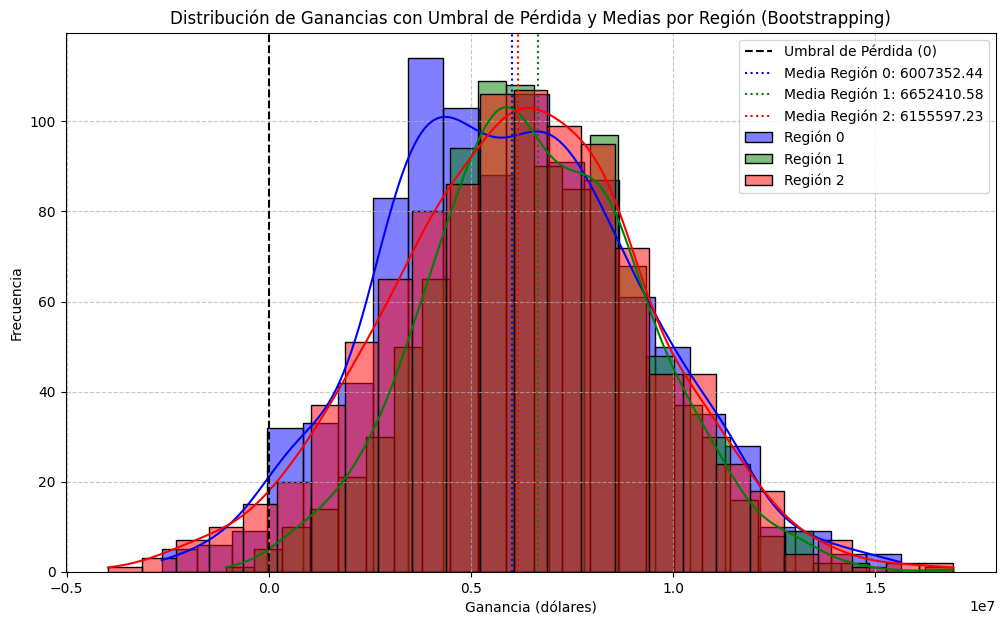

In [21]:
#Representación gráfica comparativa de la distribución de Ganancias por región después de aplicar Bootstrapping
plt.figure(figsize=(12, 7))
sns.histplot(profits_0, color='blue', label='Región 0', kde=True, alpha=0.5)
sns.histplot(profits_1, color='green', label='Región 1', kde=True, alpha=0.5)
sns.histplot(profits_2, color='red', label='Región 2', kde=True, alpha=0.5)
# Añadir linea para umbral de pérdida (Ganancia = 0)
plt.axvline(x=0, color='black', linestyle='--', label='Umbral de Pérdida (0)')
# Añadir líneas para la ganancia media de cada región
plt.axvline(x=mean_profit_0, color='blue', linestyle=':', linewidth=1.5, label=f'Media Región 0: {mean_profit_0:.2f}')
plt.axvline(x=mean_profit_1, color='green', linestyle=':', linewidth=1.5, label=f'Media Región 1: {mean_profit_1:.2f}')
plt.axvline(x=mean_profit_2, color='red', linestyle=':', linewidth=1.5, label=f'Media Región 2: {mean_profit_2:.2f}')
plt.title('Distribución de Ganancias con Umbral de Pérdida y Medias por Región (Bootstrapping)')
plt.xlabel('Ganancia (dólares)')
plt.ylabel('Frecuencia')
plt.legend()
plt.grid(True, linestyle='--', alpha=0.7)
plt.show()

En este histograma de distribución observamos lo siguiente.
- Las barras representan cada región. La altura de las barras indica con qué frecuencia se obtuvieron ciertos rangos de ganancias durante las 1000 iteraciones del bootstrapping. Las formas de los histogramas nos dan uan idea de la variabilidad. Todas las regiones muestran una distribución algo acampanada pero con diferencias en sus picos y colas. La región 1 tiene su masa principal de probabilidad más concentrada en el lado positivo, y con menos cola hacia las pérdidas.
- Las curvas sobre las barras (KDE) son una estimación de la densidad de probabilidad mostrando la forma general de la distribución. Nos muestran dónde se concentran más de los resultados de las 1000 simulaciones de bootstrapping y observamos que la curva de la región 1 tiene el pico más alto y estrecho, y tiene la cola mas corta respecto a la linea negra de Umbral de pérdida.
- Linea vertical Negra Discontinua (Umbral de Pérdida): nos marca el punto donde la ganancia es 0. Cualquier área de distribución de ganancias que esté a la izquierda de esta línea representa una pérdida.
- Comparación de medias: Podemos observar que la región 1 (línea verde) está más a la derecha que las otras 2, confirmando que tiene la ganancia mas alta. 

In [22]:
#tabla resumen
final_summary = pd.DataFrame({
    'Región': ['Región 0', 'Región 1', 'Región 2'],
    'Ganancia Promedio (dólares)': [mean_profit_0, mean_profit_1, mean_profit_2],
    'Intervalo de Confianza 95% (dólares)': [confidence_interval_0, confidence_interval_1, confidence_interval_2],
    'Riesgo de Pérdida': [f'{risk_loss_0:.2%}', f'{risk_loss_1:.2%}', f'{risk_loss_2:.2%}']
})
display(final_summary)

,Región,Ganancia Promedio (dólares),Intervalo de Confianza 95% (dólares),Riesgo de Pérdida
0,Región 0,6.007352e+06,"(129483.3113511391, 12311636.057914983)",2.00%
1,Región 1,6.652411e+06,"(1579884.8131991457, 11976415.874631526)",0.30%
2,Región 2,6.155597e+06,"(-122184.952372932, 12306444.73941316)",3.00%


Esta tabla resume claramente por qué la Región 1 es la opción más recomendada, destacando su mayor ganancia promedio y, crucialmente, el menor riesgo de pérdida, que cumple con el umbral establecido de menos del 2.5%.

## Conclusión General del Proyecto: Selección Óptima de Región para OilyGiant

Este proyecto tuvo como objetivo principal identificar la región más prometedora para la perforación de 200 nuevos pozos petroleros por parte de OilyGiant, con una inversión de 100 millones de dólares y un umbral de riesgo de pérdida máximo del 2.5%.

### Resumen de los Pasos Clave y Hallazgos:

1.  **Exploración y Preparación de Datos (Paso 1):** Se cargaron y exploraron los datos geológicos de tres regiones:`df_gd0`, `df_gd1`, `df_gd2`. Se confirmó la ausencia de valores nulos o duplicados, asegurando la calidad de los datos. Las estadísticas descriptivas y visualizaciones mostraron diferencias claras entre las regiones, especialmente en las características `f0`, `f1`, `f2` y en la variable objetivo `product` (volumen de reservas).

2.  **Entrenamiento y Evaluación de Modelos (Paso 2):** Se entrenó un modelo de Regresión Lineal para cada región. Los resultados del RMSE indicaron que el modelo para la Región 1 era significativamente más preciso (RMSE: 0.89) en comparación con la Región 0 (RMSE: 37.58) y la Región 2 (RMSE: 40.03). Sin embargo, la Región 1 presentó un volumen promedio de producto predicho más bajo (68.73 mil barriles) que las Regiones 0 y 2 (92.59 y 94.97 mil barriles, respectivamente).

3.  **Preparación para el Cálculo de Ganancias (Paso 3):** Se definieron las constantes del negocio (presupuesto, número de pozos, ingreso por unidad) y se calculó el volumen mínimo de reservas necesario por pozo para evitar pérdidas: 111.11 mil barriles. Ninguna de las regiones cumplió este umbral con su volumen promedio predicho, lo que señaló la necesidad de un análisis más profundo.

4.  **Cálculo de Ganancias por Región (Paso 4):** Se desarrolló una función para seleccionar los 200 pozos con mayor volumen predicho de una muestra de 500 y calcular la ganancia potencial. En una muestra inicial, la Región 1 mostró la mayor ganancia (aproximadamente 7.79M USD), seguida por la Región 0 (6.79M USD) y la Región 2 (4.40M USD).

5.  **Análisis de Riesgos y Ganancias con Bootstrapping (Paso 5):** Este fue el paso decisivo, utilizando 1000 iteraciones para evaluar robustamente las ganancias promedio, los intervalos de confianza y, crucialmente, el riesgo de pérdida para cada región.

### Conclusión Final y Recomendación:

Basándonos en el análisis exhaustivo de riesgo y ganancia utilizando bootstrapping, la **Región 1** es la opción óptima y recomendada para OilyGiant. Las razones son las siguientes:

*   **Mayor Ganancia Promedio:** Con una ganancia promedio de **6,652,410.58 dólares**, la Región 1 ofrece el mayor retorno de inversión esperado.
*   **Riesgo de Pérdida Extremadamente Bajo:** El riesgo de pérdida para la Región 1 es de solo **0.30%**, lo que está significativamente por debajo del umbral máximo aceptable del 2.5%. Esto la posiciona como la opción más segura.
*   **Intervalo de Confianza Robusto:** El intervalo de confianza del 95% para la Región 1 [1,579,884.81, 11,976,415.87] dólares muestra que incluso en el peor de los casos (dentro del 95% de confianza), la región sigue siendo altamente rentable, con un límite inferior positivo sustancial.

Aunque la Región 0 también presenta un riesgo de pérdida aceptable (2.00%) y una ganancia promedio decente, la Región 1 la supera en ambos aspectos. La Región 2, a pesar de una ganancia promedio similar a la Región 0, excede el umbral de riesgo con un 3.00% de probabilidad de pérdida, lo que la descarta como una opción viable bajo los criterios de OilyGiant.

En síntesis, la **Región 1** maximiza el potencial de ganancias mientras minimiza el riesgo, lo que la convierte en la elección estratégica más inteligente para la expansión de OilyGiant.